# CODE 5.2: Test Results

> **Goal:** open the test months (April to August) for the first time, apply the alarm rules that notebook 5.1 locked, and measure for both models: how many of the 4 leaks they catch, how early, and how many false alarms they raise.
>
> - **Input:** `data/processed/grid.npz` and `data/processed/windows.parquet` (3.1), `results/time_split.csv` and `results/leaks.csv` (1.2), `results/signals_used.json` (4.1), `models/isolation_forest.joblib` (4.1), `models/lstm_autoencoder.pt` (4.2) and `results/alarm_rules.json` (5.1).
> - **Output:** `results/window_scores.parquet` (the score, the error and the alarms of every window, for notebooks 5.3, 5.4 and 6.1) and `results/test_results.csv` (the results of both models). At the end you should see **ALL CHECKS PASSED**.
>
> Nothing in this notebook may change a rule. The limits come from `alarm_rules.json`, and two checks make sure that this file and the two model files are exactly the ones of notebook 5.1.

### The Rules of the Test

> These rules were fixed in notebook 1.2 (the zones) and notebook 5.1 (the alarms), before any test window got a score:
>
> - **Alarm:** 3 windows in a row above the main limit of the model. Alarms at most 60 minutes apart are one **event**. The alarm rule runs over the test windows from 1 April on.
> - **Zones:** every window gets the zone of its end time. **Warning zone:** the 24 hours before a leak starts. **Leak:** from its start to its reported end. **Ignored zone:** the 48 hours after the reported end. **Healthy:** all other time.
> - **Caught:** at least one alarm in the warning zone or during the leak. **Lead time:** the leak start minus the first such alarm. A negative lead time means the first alarm came after the start: caught, but late.
> - **False alarms:** the events formed by the alarms in healthy time, per week of watched healthy time (healthy windows times 5 minutes).
> - **Ignored zone:** its alarms are counted and shown, but count neither as right nor as false.
> - Nothing is left out in the test months: unlike March in notebook 5.1, every hour counts.
>
> The picture is the one of notebook 1.2.

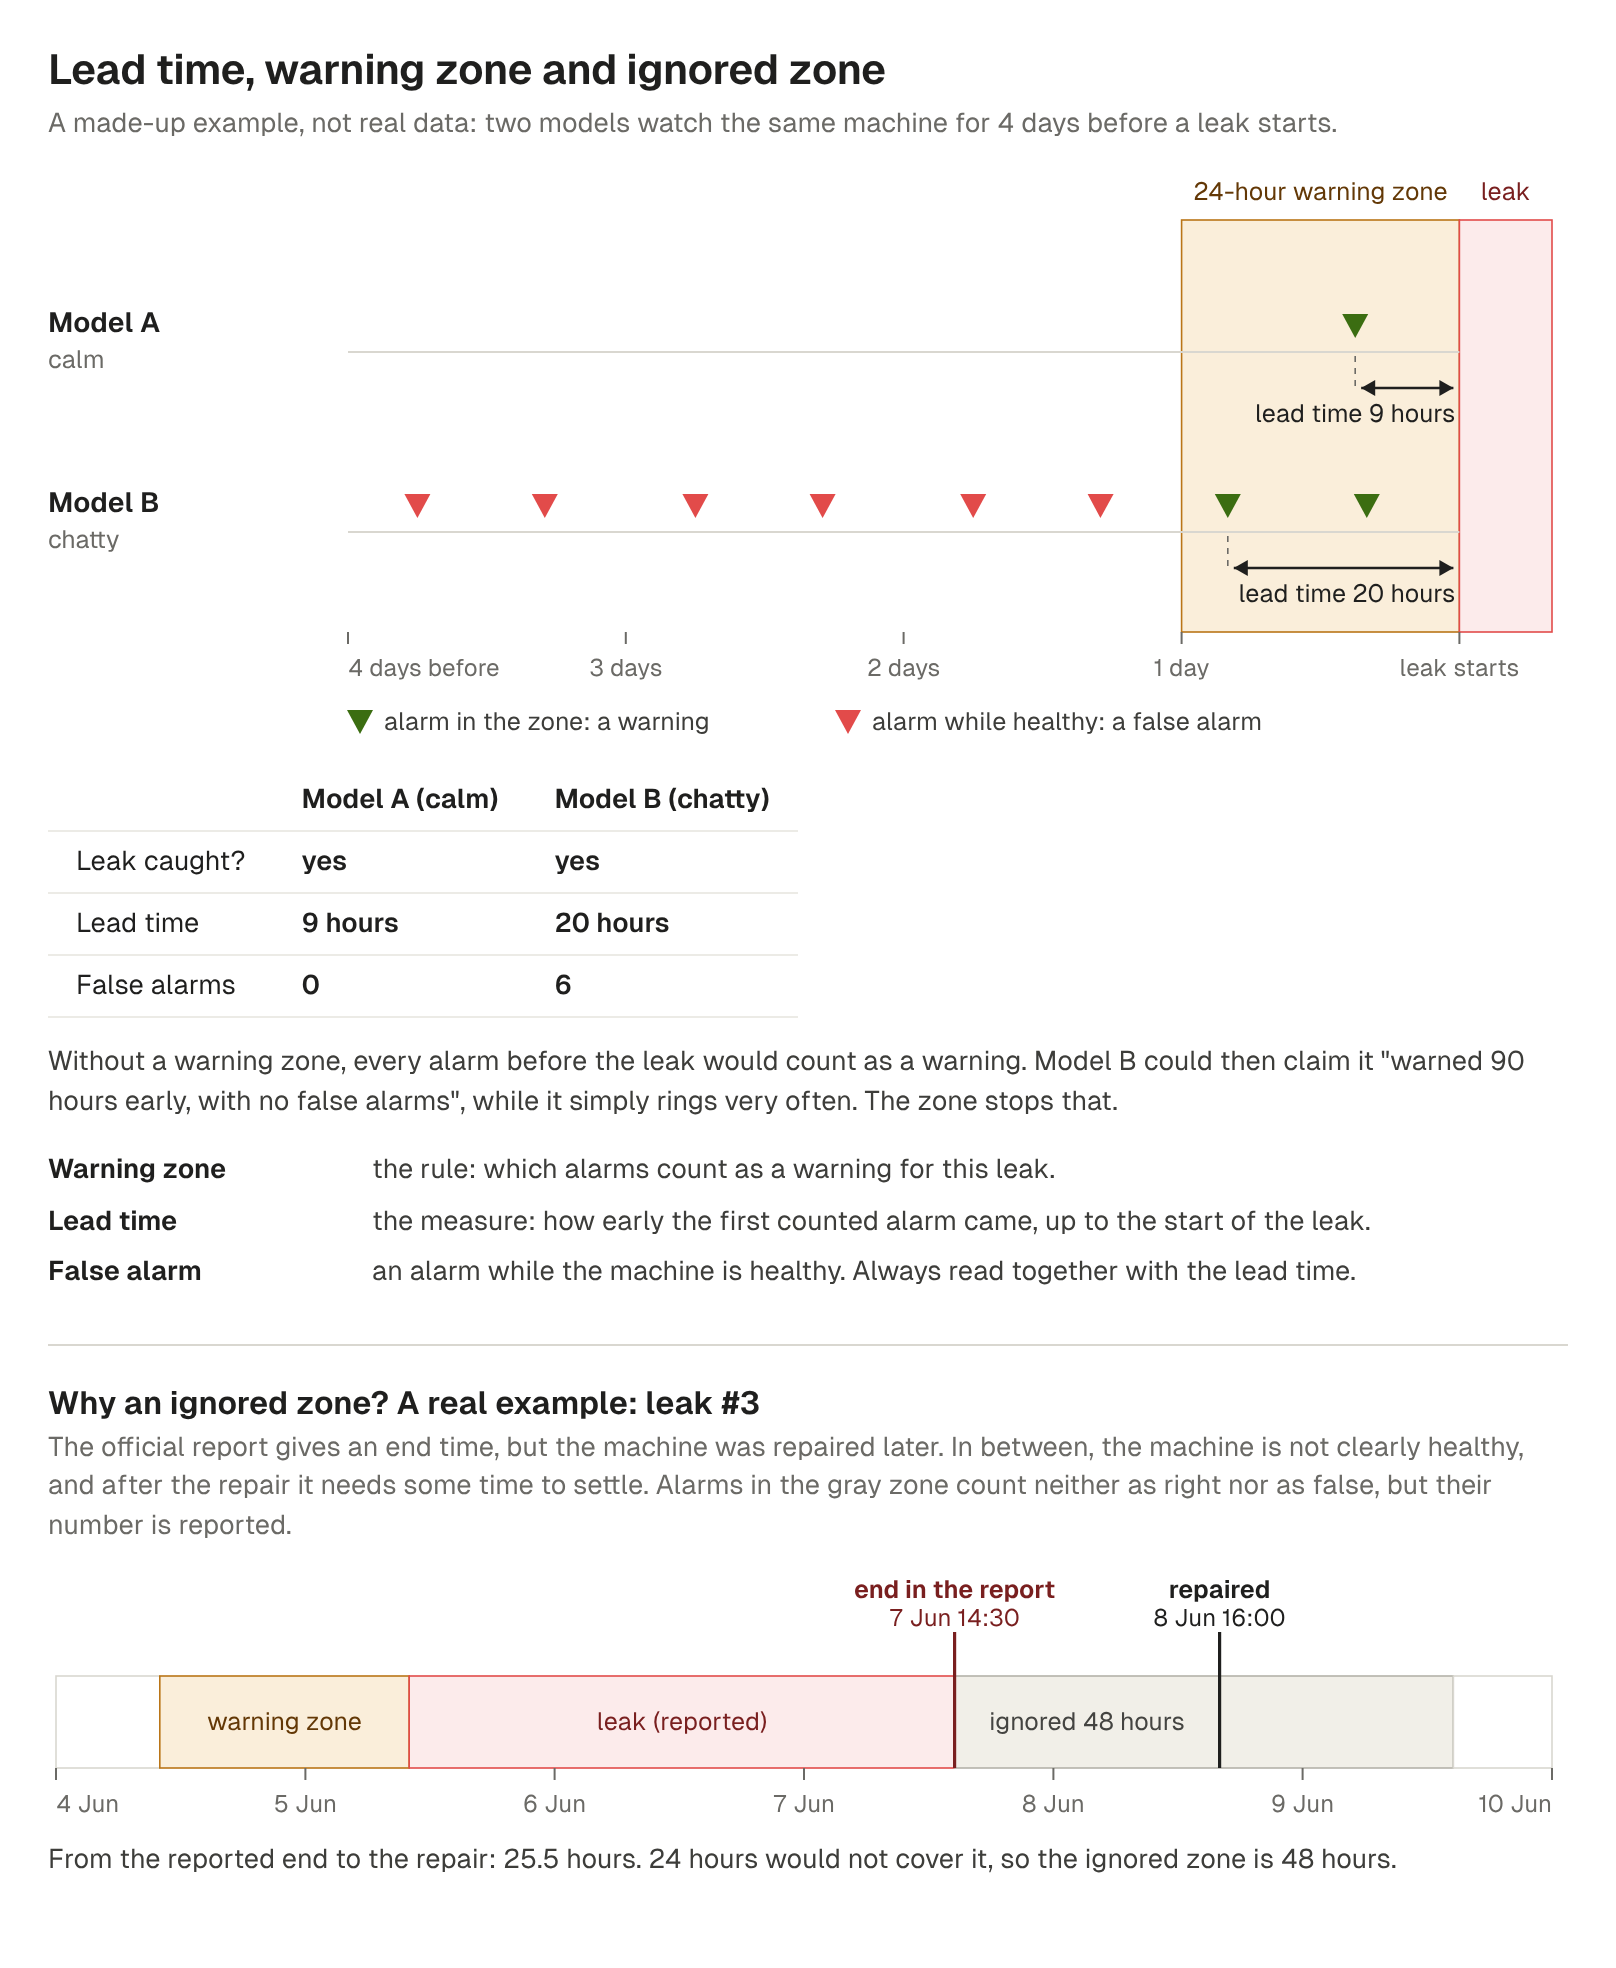

## Import Libraries & Variables

### Import Libraries

> - `os`, `json`, `hashlib`: folders and file paths, the rules file, and fingerprints of files.
> - `numpy`, `pandas`: numbers and tables.
> - `matplotlib`: charts. `matplotlib.dates` turns a date into a position on the time axis, for the leak numbers above the first chart.
> - `joblib`: loads the Isolation Forest of notebook 4.1.
> - `torch` (PyTorch): rebuilds the LSTM autoencoder of notebook 4.2 and lets it redraw the windows.
> - `tqdm`: shows a progress bar while the LSTM redraws about 47,000 windows.

In [1]:
import os
import json
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import joblib
import torch
from tqdm import tqdm

### Variables

#### Folder Paths

> The inputs from notebooks 1.2, 3.1, 4.1, 4.2 and 5.1, and the two files this notebook writes.

In [2]:
ROOT_DIR = os.getcwd()
while not os.path.isfile(os.path.join(ROOT_DIR, "requirements.txt")) and ROOT_DIR != os.path.dirname(ROOT_DIR):
    ROOT_DIR = os.path.dirname(ROOT_DIR)

PROCESSED_DIR = os.path.join(ROOT_DIR, "data", "processed")
GRID_FILE = os.path.join(PROCESSED_DIR, "grid.npz")
WINDOWS_FILE = os.path.join(PROCESSED_DIR, "windows.parquet")
RESULTS_DIR = os.path.join(ROOT_DIR, "results")
SPLIT_FILE = os.path.join(RESULTS_DIR, "time_split.csv")
LEAKS_FILE = os.path.join(RESULTS_DIR, "leaks.csv")
SIGNALS_FILE = os.path.join(RESULTS_DIR, "signals_used.json")
RULES_FILE = os.path.join(RESULTS_DIR, "alarm_rules.json")
SCORES_FILE = os.path.join(RESULTS_DIR, "window_scores.parquet")
SUMMARY_FILE = os.path.join(RESULTS_DIR, "test_results.csv")
MODELS_DIR = os.path.join(ROOT_DIR, "models")
FOREST_FILE = os.path.join(MODELS_DIR, "isolation_forest.joblib")
LSTM_FILE = os.path.join(MODELS_DIR, "lstm_autoencoder.pt")
print("Project folder found:", os.path.basename(ROOT_DIR))

Project folder found: predictive-maintenance-metropt


#### Settings

> - `SIGNALS`, `OIL_COLUMN`, `WINDOW_STEPS`, `EVAL_BATCH`: as in notebook 4.2, to cut the windows for the LSTM and measure their errors.
> - `CHUNK_WINDOWS`: the LSTM redraws the windows in chunks of this many windows, so the memory stays small. It is a multiple of `EVAL_BATCH`, so the groups of windows are the same as in notebooks 4.2 and 5.1.
> - `WARNING_HOURS`, `IGNORED_HOURS`: the zones of notebook 1.2.
> - `MINUTES_PER_WEEK`: to count false alarms per week.
> - `MODEL_NAMES`, `SPLIT_NAMES`, `ZONE_ORDER`, `ZONE_COLORS`: names and colors for tables and charts.
> - `VIEW_BEFORE_HOURS`: the charts of each leak start this many hours before its warning zone.
>
> The alarm rule itself (3 in a row, the 60-minute merge) and the limits are not set here: they are read from `alarm_rules.json`.

In [3]:
ANALOG_COLUMNS = ["TP2", "TP3", "H1", "DV_pressure", "Reservoirs", "Oil_temperature", "Motor_current"]
DIGITAL_COLUMNS = ["COMP", "DV_eletric", "Towers", "MPG", "LPS", "Pressure_switch", "Oil_level", "Caudal_impulses"]
SIGNALS = ANALOG_COLUMNS + DIGITAL_COLUMNS
OIL_COLUMN = "Oil_temperature"
WINDOW_STEPS = 360
EVAL_BATCH = 512
CHUNK_WINDOWS = 8192

WARNING_HOURS = 24
IGNORED_HOURS = 48
MINUTES_PER_WEEK = 7 * 24 * 60

MODEL_NAMES = {"isolation_forest": "Isolation Forest", "lstm_autoencoder": "LSTM autoencoder"}
SPLIT_NAMES = {"train": "February", "validation": "March", "test": "April to August"}
ZONE_ORDER = ["healthy", "warning", "leak", "ignored"]
ZONE_COLORS = {"warning": "#EF9F27", "leak": "#E24B4A", "ignored": "#B4B2A9"}
VIEW_BEFORE_HOURS = 48

## Functions

### Record a Check

> `check()` prints PASS or FAIL for one check and stores the result in `results`.

In [4]:
results = {}

def check(name, ok):
    results[name] = bool(ok)
    print(("PASS  " if ok else "FAIL  ") + name)

### Cut Many Windows at Once (from 4.2)

> `cut_windows()` is copied unchanged from notebook 4.2.

In [5]:
def cut_windows(grid_values, end_indices, window_steps, oil_index):
    ticks = end_indices[:, None] - window_steps + 1 + np.arange(window_steps)[None, :]
    windows = grid_values[ticks]
    windows[:, :, oil_index] -= windows[:, :1, oil_index]
    return windows

### The LSTM Autoencoder (from 4.2)

> `LSTMAutoencoder` is copied unchanged from notebook 4.2, so the saved weights fit into it.

In [6]:
class LSTMAutoencoder(torch.nn.Module):
    def __init__(self, n_signals, memory_size):
        super().__init__()
        self.encoder = torch.nn.LSTM(input_size=n_signals, hidden_size=memory_size, batch_first=True)
        self.decoder = torch.nn.LSTM(input_size=memory_size, hidden_size=memory_size, batch_first=True)
        self.output = torch.nn.Linear(in_features=memory_size, out_features=n_signals)

    def forward(self, windows):
        _, (memory, _) = self.encoder(windows)
        note = memory[-1].unsqueeze(1).repeat(1, windows.shape[1], 1)
        redrawn, _ = self.decoder(note)
        return self.output(redrawn)

### Measure the Errors (from 4.2)

> `window_errors()` is copied unchanged from notebook 4.2: the error of every window, and its error for every signal. Notebook 5.3 uses the errors per signal to explain the alarms, so this notebook saves them.

In [7]:
def window_errors(model, windows, batch_size):
    model.eval()
    parts = []
    with torch.no_grad():
        for start in range(0, len(windows), batch_size):
            batch = windows[start:start + batch_size]
            parts.append((model(batch) - batch).abs().mean(dim=1).cpu())
    per_signal = torch.cat(parts).numpy()
    return per_signal.mean(axis=1), per_signal

### Errors in Chunks

> `lstm_errors_in_chunks()` cuts the windows of one part (February, March or the test months) chunk by chunk, lets the LSTM redraw them with `window_errors()`, and puts the errors of all chunks together. Only one chunk is in memory at a time.

In [8]:
def lstm_errors_in_chunks(model, grid_values, end_indices, signal_columns, window_steps, oil_index, chunk_windows, batch_size, device, label):
    means, per_signal = [], []
    for start in tqdm(range(0, len(end_indices), chunk_windows), desc=label):
        windows = cut_windows(grid_values=grid_values, end_indices=end_indices[start:start + chunk_windows], window_steps=window_steps, oil_index=oil_index)
        inputs = torch.from_numpy(np.ascontiguousarray(windows[:, :, signal_columns])).to(device)
        chunk_means, chunk_signals = window_errors(model=model, windows=inputs, batch_size=batch_size)
        means.append(chunk_means)
        per_signal.append(chunk_signals)
    return np.concatenate(means), np.vstack(per_signal)

### Score Windows with the Forest (from 4.1)

> `anomaly_score()` is copied unchanged from notebook 4.1.

In [9]:
def anomaly_score(model, features):
    return -model.score_samples(features)

### Fingerprints (from 5.1)

> `file_fingerprint()` and `rules_fingerprint()` are copied unchanged from notebook 5.1. They compute the same codes as notebook 5.1 did, so we can compare.

In [10]:
def file_fingerprint(path):
    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

In [11]:
def rules_fingerprint(rules):
    text = json.dumps({key: value for key, value in rules.items() if key != "fingerprint"}, sort_keys=True)
    return hashlib.sha256(text.encode("utf-8")).hexdigest()

### Which Zone Is a Time In? (from 1.2)

> `zone_of()` is copied unchanged from notebook 1.2: *warning* from 24 hours before a start up to the start, *leak* from the start to the end (both included), *ignored* from just after the end up to 48 hours after it, and *healthy* for all other times. It also returns the number of the leak each zone belongs to (0 for healthy).

In [12]:
def zone_of(times, leaks, warning_hours, ignored_hours):
    zones = pd.Series("healthy", index=times.index)
    leak_numbers = pd.Series(0, index=times.index, dtype="int8")
    for row in leaks.itertuples():
        stretches = {
            "warning": (times >= row.start - pd.Timedelta(hours=warning_hours)) & (times < row.start),
            "leak": (times >= row.start) & (times <= row.end),
            "ignored": (times > row.end) & (times <= row.end + pd.Timedelta(hours=ignored_hours)),
        }
        for zone, inside in stretches.items():
            zones[inside] = zone
            leak_numbers[inside] = row.leak
    return zones, leak_numbers

### Alarms and Events (from 5.1)

> `alarm_windows()` and `find_events()` are copied unchanged from notebook 5.1: an alarm at every window that is the 3rd (or later) window in a row above the limit, and events made of alarms at most `merge_gap_minutes` apart.

In [13]:
def alarm_windows(scores, ends, limit, in_a_row, step_minutes):
    above = pd.Series(scores > limit)
    restart = ~above | pd.Series(ends.diff().to_numpy() != np.timedelta64(step_minutes, "m"))
    run = above.astype(int).groupby(restart.cumsum()).cumsum()
    return (run >= in_a_row).to_numpy()

In [14]:
def find_events(alarms, counted, ends, merge_gap_minutes):
    times = ends[alarms & counted].reset_index(drop=True)
    new_event = times.diff().isna() | (times.diff() > pd.Timedelta(minutes=merge_gap_minutes))
    events = times.groupby(new_event.cumsum()).agg(["min", "max", "size"])
    return events.rename(columns={"min": "first_alarm", "max": "last_alarm", "size": "alarms"}).reset_index(drop=True)

### Judge Each Leak

> `judge_leaks()` looks at the alarms of one model around every leak:
>
> - **caught:** is there at least one alarm in the warning zone or during the leak?
> - **first alarm** and **lead time:** the first such alarm, and how many hours before the leak start it came (negative when it came after the start);
> - how many alarms fell in the warning zone, during the leak, and in the ignored zone.

In [15]:
def judge_leaks(alarms, ends, zones, leak_numbers, leaks):
    rows = []
    for row in leaks.itertuples():
        own = alarms & (leak_numbers == row.leak)
        in_time = own & np.isin(zones, ["warning", "leak"])
        first = ends[in_time].min() if in_time.any() else pd.NaT
        rows.append({"leak": row.leak, "caught": bool(in_time.any()), "first_alarm": first,
                     "lead_time_hours": (row.start - first) / pd.Timedelta(hours=1) if in_time.any() else np.nan,
                     "alarms_in_warning_zone": int((own & (zones == "warning")).sum()),
                     "alarms_during_leak": int((own & (zones == "leak")).sum()),
                     "alarms_in_ignored_zone": int((own & (zones == "ignored")).sum())})
    return pd.DataFrame(rows)

## Load Everything

### Read the Files

> This time all windows are kept: February and March, and for the first time the test months. The rules come from the file of notebook 5.1, and its fingerprint must still match its content.

In [16]:
with np.load(GRID_FILE) as saved:
    grid_values, grid_signals = saved["values"], saved["signals"].tolist()
df_windows = pd.read_parquet(WINDOWS_FILE)
split_table = pd.read_csv(SPLIT_FILE).set_index("split")
test_from = pd.Timestamp(split_table.loc["test", "from"])
leaks = pd.read_csv(LEAKS_FILE, parse_dates=["warning_from", "start", "end", "ignored_until"], keep_default_na=False)
with open(SIGNALS_FILE, encoding="utf-8") as f:
    signals_info = json.load(f)
with open(RULES_FILE, encoding="utf-8") as f:
    rules = json.load(f)

FEATURE_COLUMNS = signals_info["isolation_forest_features"]
IN_A_ROW, STEP_MINUTES = rules["alarm_rule"]["in_a_row"], rules["alarm_rule"]["window_step_minutes"]
MERGE_GAP_MINUTES = rules["alarm_rule"]["merge_gap_minutes"]
LIMITS = {model: rules["limits"][model]["main"] for model in MODEL_NAMES}

display(df_windows.groupby("split")["end"].agg(windows="size", first_end="min", last_end="max").reindex(list(SPLIT_NAMES)).rename(index=SPLIT_NAMES))
print(f"Alarm rule: {IN_A_ROW} windows in a row, events merged when alarms are at most {MERGE_GAP_MINUTES} minutes apart")
print("Locked main limits:", {MODEL_NAMES[model]: round(limit, 4) for model, limit in LIMITS.items()})
check("the rules file is exactly the one notebook 5.1 locked (its fingerprint matches its content)", rules_fingerprint(rules=rules) == rules["fingerprint"])

,windows,first_end,last_end
split,,,
February,6790,2020-02-01 01:00:00,2020-02-28 23:55:00
March,7194,2020-03-01 05:00:00,2020-03-31 23:55:00
April to August,33507,2020-04-01 00:00:00,2020-09-01 03:55:00


Alarm rule: 3 windows in a row, events merged when alarms are at most 60 minutes apart
Locked main limits: {'Isolation Forest': 0.7326, 'LSTM autoencoder': 0.78}
PASS  the rules file is exactly the one notebook 5.1 locked (its fingerprint matches its content)


### Load the Two Models and Compare Their Fingerprints

> The models are loaded as in notebook 5.1. Then the fingerprints of the two model files are compared with the ones saved in `alarm_rules.json`: the limits belong to these exact files. If a model had been trained again, this check would fail.

In [17]:
forest = joblib.load(FOREST_FILE)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
saved_lstm = torch.load(LSTM_FILE, map_location=device, weights_only=True)
lstm = LSTMAutoencoder(n_signals=len(saved_lstm["signals"]), memory_size=saved_lstm["memory_size"]).to(device)
lstm.load_state_dict(saved_lstm["state_dict"])
fingerprints = {os.path.basename(path): file_fingerprint(path=path) for path in [FOREST_FILE, LSTM_FILE]}

for name, value in fingerprints.items():
    print(f"{name}: {value[:16]}... | saved by notebook 5.1: {rules['model_files'][name][:16]}...")
print("LSTM runs on:", device.type)
check("the two model files are exactly the ones the limits were set for (their fingerprints match)", fingerprints == rules["model_files"])

isolation_forest.joblib: 5097501b4dda5e40... | saved by notebook 5.1: 5097501b4dda5e40...
lstm_autoencoder.pt: 84626161ecb960ac... | saved by notebook 5.1: 84626161ecb960ac...
LSTM runs on: cuda
PASS  the two model files are exactly the ones the limits were set for (their fingerprints match)


## Score Every Window

### The Score and the Error of Every Window

> Every window of every month gets its score from the forest and its error from the LSTM. The LSTM goes part by part (February, March, the test months), in the same groups of windows as in notebooks 4.2 and 5.1, so February and March get exactly the same errors as there. The table shows the middle (median) and the highest value of every part.

In [18]:
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
df_windows["isolation_forest"] = anomaly_score(model=forest, features=df_windows[FEATURE_COLUMNS])
signal_columns = [grid_signals.index(signal) for signal in signals_info["signals"]]
signal_errors = np.full((len(df_windows), len(signal_columns)), np.nan, dtype="float32")
df_windows["lstm_autoencoder"] = np.nan
for split, name in SPLIT_NAMES.items():
    mask = (df_windows["split"] == split).to_numpy()
    means, per_signal = lstm_errors_in_chunks(model=lstm, grid_values=grid_values, end_indices=df_windows.loc[mask, "end_index"].to_numpy(),
                                              signal_columns=signal_columns, window_steps=WINDOW_STEPS, oil_index=grid_signals.index(OIL_COLUMN),
                                              chunk_windows=CHUNK_WINDOWS, batch_size=EVAL_BATCH, device=device, label=f"LSTM errors, {name}")
    df_windows.loc[mask, "lstm_autoencoder"] = means
    signal_errors[mask] = per_signal

summary = pd.DataFrame({(MODEL_NAMES[model], statistic): df_windows.groupby("split")[model].agg(statistic) for model in MODEL_NAMES for statistic in ["median", "max"]})
display(summary.reindex(list(SPLIT_NAMES)).rename(index=SPLIT_NAMES).round(3))
check("every window of every month has a finite score and error", np.isfinite(df_windows[list(MODEL_NAMES)].to_numpy()).all() and np.isfinite(signal_errors).all())

LSTM errors, April to August: 100%|██████████| 5/5 [00:02<00:00,  2.35it/s]


Isolation Forest        LSTM autoencoder       
                          median    max           median    max
split                                                          
February                   0.425  0.735            0.074  0.458
March                      0.610  0.756            0.250  2.738
April to August            0.623  0.757            0.272  3.902

PASS  every window of every month has a finite score and error


> **What we see:** February and March come out exactly as in notebooks 4.1, 4.2 and 5.1 (the next section checks this to the last digit). In the test months, the middle score of the forest and the middle error of the LSTM are close to March, only a little higher: on the whole, the test months look about as unusual as March. The highest values tell the two models apart again: the forest stays under its ceiling, barely above its highest March score, while the LSTM reaches errors well above anything it saw in March.

### March Again: the Same Scores as in Notebook 5.1?

> Every locked limit is one of the March scores of notebook 5.1. If the models score March exactly as they did there, each limit must appear again, to the last digit, among the March scores computed here. And with every March window counted, the what-if limits must give the same number of false alarm events as in notebook 5.1.

In [19]:
df_march = df_windows[df_windows["split"] == "validation"].reset_index(drop=True)
march_counted = np.ones(len(df_march), dtype=bool)
for model in MODEL_NAMES:
    found = [version for version in ["main", "all_counted"] if np.isin(rules["limits"][model][version], df_march[model].to_numpy())]
    alarms = alarm_windows(scores=df_march[model].to_numpy(), ends=df_march["end"], limit=rules["limits"][model]["all_counted"],
                           in_a_row=IN_A_ROW, step_minutes=STEP_MINUTES)
    events = find_events(alarms=alarms, counted=march_counted, ends=df_march["end"], merge_gap_minutes=MERGE_GAP_MINUTES)
    print(f"{MODEL_NAMES[model]}: limits found again among the March scores: {found} | what-if events in March: {len(events)} "
          f"(notebook 5.1: {rules['march'][model]['all_counted']['false_alarm_events']})")
    results_ok = len(found) == 2 and len(events) == rules["march"][model]["all_counted"]["false_alarm_events"]
    check(f"{MODEL_NAMES[model]} scores March exactly as in notebook 5.1", results_ok)

Isolation Forest: limits found again among the March scores: ['main', 'all_counted'] | what-if events in March: 3 (notebook 5.1: 3)
PASS  Isolation Forest scores March exactly as in notebook 5.1
LSTM autoencoder: limits found again among the March scores: ['main', 'all_counted'] | what-if events in March: 3 (notebook 5.1: 3)
PASS  LSTM autoencoder scores March exactly as in notebook 5.1


## The Test Months

### The Zone of Every Test Window

> Every test window gets the zone of its end time, with `zone_of()` of notebook 1.2. The table shows, for every leak, how many hours of each zone were watched by at least one window. Hours without a complete window (the train switched off, or data missing) are watched by no model, so no model can raise an alarm there.

In [20]:
df_test = df_windows[df_windows["split"] == "test"].reset_index(drop=True)
df_test["zone"], df_test["leak"] = zone_of(times=df_test["end"], leaks=leaks, warning_hours=WARNING_HOURS, ignored_hours=IGNORED_HOURS)

watched = df_test[df_test["leak"] > 0].groupby(["leak", "zone"]).size().unstack(fill_value=0).reindex(columns=["warning", "leak", "ignored"], fill_value=0)
watched = (watched * STEP_MINUTES / 60).rename(columns={"warning": "warning zone (of 24 h)", "leak": "during the leak", "ignored": "ignored zone (of 48 h)"})
watched.insert(2, "leak length (h)", ((leaks["end"] - leaks["start"]) / pd.Timedelta(hours=1)).to_numpy())
healthy = (df_test["zone"] == "healthy").to_numpy()
healthy_weeks = healthy.sum() * STEP_MINUTES / MINUTES_PER_WEEK

display(watched.round(1))
print(f"Test windows: {len(df_test):,} | healthy: {healthy.sum():,} windows = {healthy_weeks:.1f} weeks watched")
check("every test window has one zone, and all 4 leaks with their zones lie in the test months",
      df_test["zone"].isin(ZONE_ORDER).all() and (leaks["warning_from"] >= test_from).all() and set(df_test["leak"]) == {0} | set(leaks["leak"]))

zone,warning zone (of 24 h),during the leak,leak length (h),ignored zone (of 48 h)
leak,,,,
1,18.9,22.9,24.0,46.5
2,18.8,6.6,6.5,40.1
3,24.0,45.8,52.5,24.2
4,16.0,3.6,4.5,38.4


Test windows: 33,507 | healthy: 29,838 windows = 14.8 weeks watched
PASS  every test window has one zone, and all 4 leaks with their zones lie in the test months


> **What we see:** not every hour of the zones was watched. Most warning zones have only part of their 24 hours with a window, and the ignored zone of leak 3 only about half of its 48 hours (see the table). In those hours no model can raise an alarm, for both models alike. "During the leak" can be a few minutes longer than the leak itself, because the windows at its start and at its end both count. The healthy test windows add up to the watched healthy weeks printed above: the base for the false alarms per week.

### Alarms with the Locked Limits

> The alarm rule runs over the test windows, from 1 April on, with the main limit of each model. The table counts the alarm windows in every zone.

In [21]:
for model in MODEL_NAMES:
    df_test[f"{model}_alarm"] = alarm_windows(scores=df_test[model].to_numpy(), ends=df_test["end"], limit=LIMITS[model],
                                              in_a_row=IN_A_ROW, step_minutes=STEP_MINUTES)
alarm_table = pd.DataFrame({MODEL_NAMES[model]: df_test.groupby("zone")[f"{model}_alarm"].sum() for model in MODEL_NAMES}).reindex(ZONE_ORDER).fillna(0).astype(int)
alarm_table.insert(0, "windows in the zone", df_test.groupby("zone").size().reindex(ZONE_ORDER).fillna(0).astype(int))
display(alarm_table)
for model in MODEL_NAMES:
    print(f"{MODEL_NAMES[model]}: test windows above the limit {(df_test[model] > LIMITS[model]).mean():.1%} | alarm windows {df_test[f'{model}_alarm'].sum():,}")

,windows in the zone,Isolation Forest,LSTM autoencoder
zone,,,
healthy,29838,174,1453
warning,933,0,103
leak,946,46,932
ignored,1790,1,45


Isolation Forest: test windows above the limit 1.0% | alarm windows 221
LSTM autoencoder: test windows above the limit 7.9% | alarm windows 2,533


> **What we see:** the LSTM raises many more alarm windows than the forest. Most alarm windows of both models fall in healthy time, but many of them belong to the same few events (the next sections count events). During the leaks the LSTM rings in almost every watched window, the forest only in a small part of them. Only the LSTM has alarms in a warning zone.

### The Test Months at a Glance

> Every test window at its end time, for both models. The colored bands are the zones of the 4 leaks (orange: warning zone, red: the leak, grey: ignored zone), numbered at the top. The dashed line is the locked limit, red dots are alarm windows, and the black triangles at the top mark the start of every false alarm event.

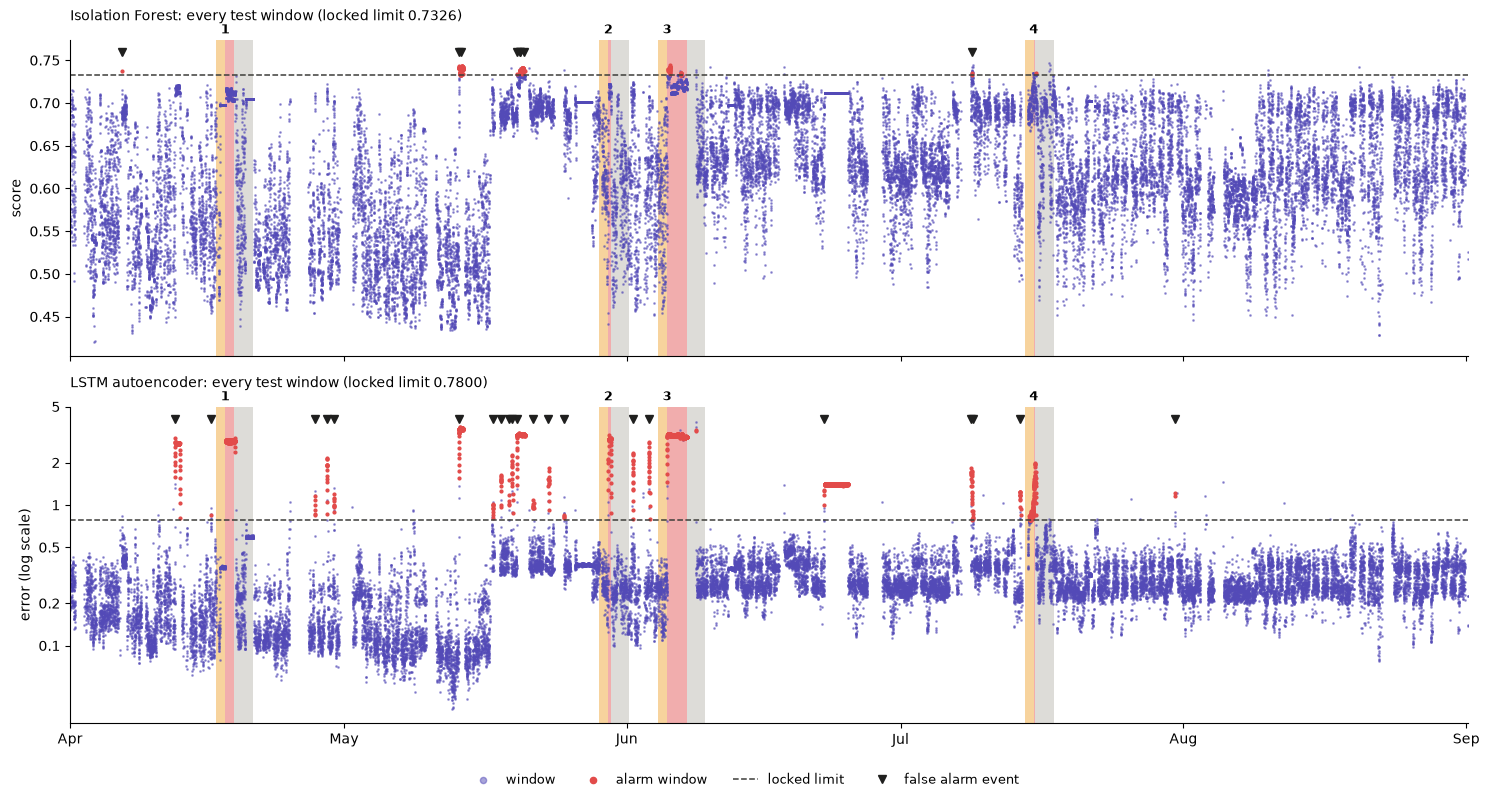

In [22]:
false_events = {model: find_events(alarms=df_test[f"{model}_alarm"].to_numpy(), counted=healthy, ends=df_test["end"], merge_gap_minutes=MERGE_GAP_MINUTES)
                for model in MODEL_NAMES}
months = pd.date_range(test_from, df_test["end"].max(), freq="MS")
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
for ax, model in zip(axes, MODEL_NAMES):
    for row in leaks.itertuples():
        ax.axvspan(row.warning_from, row.start, color=ZONE_COLORS["warning"], alpha=0.45, linewidth=0)
        ax.axvspan(row.start, row.end, color=ZONE_COLORS["leak"], alpha=0.45, linewidth=0)
        ax.axvspan(row.end, row.ignored_until, color=ZONE_COLORS["ignored"], alpha=0.45, linewidth=0)
        ax.text(mdates.date2num(row.start), 1.02, str(row.leak), transform=ax.get_xaxis_transform(), ha="center", fontsize=9, fontweight="bold")
    alarm = df_test[f"{model}_alarm"].to_numpy()
    ax.scatter(df_test.loc[~alarm, "end"], df_test.loc[~alarm, model], s=1, color="#534AB7", alpha=0.5, label="window")
    ax.scatter(df_test.loc[alarm, "end"], df_test.loc[alarm, model], s=4, color="#E24B4A", label="alarm window")
    ax.axhline(LIMITS[model], color="#3D3D3A", linestyle="--", linewidth=1.1, label="locked limit")
    ax.plot(false_events[model]["first_alarm"], np.full(len(false_events[model]), 0.96), linestyle="none", marker="v", markersize=6,
            color="#1F1F1E", transform=ax.get_xaxis_transform(), label="false alarm event")
    if model == "lstm_autoencoder":
        ax.set_yscale("log")
        ax.set_yticks([0.1, 0.2, 0.5, 1, 2, 5], labels=["0.1", "0.2", "0.5", "1", "2", "5"])
        ax.minorticks_off()
    ax.set_ylabel("error (log scale)" if model == "lstm_autoencoder" else "score")
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.set_title(f"{MODEL_NAMES[model]}: every test window (locked limit {LIMITS[model]:.4f})", fontsize=10, loc="left", pad=14)
axes[-1].set_xticks(months, labels=months.strftime("%b"))
axes[-1].set_xlim(test_from, df_test["end"].max())
legend = fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4, frameon=False, fontsize=9)
legend.legend_handles[0].set_sizes([20])
legend.legend_handles[1].set_sizes([20])
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

> **What we see:** most of the time both models stay under their limits. The scores of the forest bunch up under its ceiling, as in March, and cross the limit only in a few short moments. The LSTM crosses its limit more often, in clusters: around the four leaks, but also in healthy weeks, especially in May. A few long flat lines stand out, with many windows in a row at exactly the same value. The next section looks at them.

### Hours with Frozen Readings

> The chart above shows long flat lines: many windows in a row with exactly the same score. In these hours **none of the 7 analog readings moved at all**: every pressure, the oil temperature and the motor current kept one and the same value, for hours and sometimes days. Real sensors always move a little, so the readings were frozen: the recorder kept writing rows, but the values were stuck.
>
> We mark a window as **frozen** when, for each analog signal, its lowest and highest value in the hour are the same. The table lists every stretch of frozen windows in the test months, the zones it touches, and the alarms of each model in it. This only describes the data: the rules stay as they are, and frozen hours count like any other hour.

In [23]:
moved = [df_windows[f"{column}_min"] != df_windows[f"{column}_max"] for column in ANALOG_COLUMNS if column != OIL_COLUMN]
df_windows["frozen"] = ~np.logical_or.reduce(moved + [df_windows[f"{OIL_COLUMN}_range"] != 0])
df_test["frozen"] = df_windows.loc[df_windows["split"] == "test", "frozen"].to_numpy()

frozen = df_test[df_test["frozen"]]
new_stretch = frozen["end"].diff() != pd.Timedelta(minutes=STEP_MINUTES)
frozen_table = frozen.groupby(new_stretch.cumsum().to_numpy()).agg(first_window_end=("end", "min"), last_window_end=("end", "max"), windows=("end", "size"),
                                                                   zones=("zone", lambda zones: ", ".join(zone for zone in ZONE_ORDER if zone in set(zones))),
                                                                   forest_alarms=("isolation_forest_alarm", "sum"), lstm_alarms=("lstm_autoencoder_alarm", "sum"))
frozen_table.insert(3, "hours", frozen_table["windows"] * STEP_MINUTES / 60)
display(frozen_table.assign(first_window_end=frozen_table["first_window_end"].dt.strftime("%d %b %H:%M"),
                            last_window_end=frozen_table["last_window_end"].dt.strftime("%d %b %H:%M")).round(1).reset_index(drop=True))
print("Frozen windows:", {name: int(df_windows.loc[df_windows["split"] == split, "frozen"].sum()) for split, name in SPLIT_NAMES.items()},
      f"| share of the test windows: {df_test['frozen'].mean():.1%}")
for row in leaks.itertuples():
    zone = (df_test["leak"] == row.leak) & (df_test["zone"] == "warning")
    print(f"Warning zone of leak {row.leak}: {zone.sum() * STEP_MINUTES / 60:.1f} hours watched, of them frozen: {(zone & df_test['frozen']).sum() * STEP_MINUTES / 60:.1f}")

,first_window_end,last_window_end,windows,hours,zones,forest_alarms,lstm_alarms
0,17 Apr 10:25,18 Apr 00:15,167,13.9,"warning, leak",0,0
1,20 Apr 05:50,21 Apr 01:15,234,19.5,"healthy, ignored",0,0
2,26 May 10:20,27 May 13:40,329,27.4,healthy,0,0
3,27 May 14:55,28 May 03:15,149,12.4,healthy,0,0
4,12 Jun 03:05,12 Jun 17:05,169,14.1,healthy,0,0
5,22 Jun 16:10,25 Jun 05:05,732,61.0,healthy,0,732
6,21 Jul 14:45,21 Jul 22:00,88,7.3,healthy,0,0
7,22 Jul 07:45,22 Jul 13:00,64,5.3,healthy,0,0


Frozen windows: {'February': 0, 'March': 0, 'April to August': 1932} | share of the test windows: 5.8%
Warning zone of leak 1: 18.9 hours watched, of them frozen: 13.6
Warning zone of leak 2: 18.8 hours watched, of them frozen: 0.0
Warning zone of leak 3: 24.0 hours watched, of them frozen: 0.0
Warning zone of leak 4: 16.0 hours watched, of them frozen: 0.0


> **What we see:** frozen readings are new in the test months: February and March have none, so neither model learned what they look like. They cover a few percent of the test windows, in a handful of stretches (see the table). Two of them matter for the results:
>
> - Most watched hours of the warning zone of leak 1 are frozen. In those hours, no model could see what the compressor did before that leak.
> - In the long stretch of 22 to 25 June, the frozen readings show a pump that is on and a pressure that never moves. To the LSTM this looks much like the hours without a pump break of March, so it raises one long false alarm there. The forest raises no alarm in any frozen stretch.

### Did the Models Catch the Leaks?

> For every leak and both models: was it caught, when came the first alarm in the warning zone or during the leak, how many hours before the start was that (the lead time), and how many alarms fell in each zone.

In [24]:
leak_results = pd.concat([judge_leaks(alarms=df_test[f"{model}_alarm"].to_numpy(), ends=df_test["end"], zones=df_test["zone"].to_numpy(),
                                      leak_numbers=df_test["leak"].to_numpy(), leaks=leaks).assign(model=MODEL_NAMES[model])
                          for model in MODEL_NAMES], ignore_index=True)
shown = leak_results.assign(first_alarm=leak_results["first_alarm"].dt.strftime("%d %b %H:%M").fillna("none"),
                            lead_time_hours=leak_results["lead_time_hours"].round(1))
display(shown.set_index(["model", "leak"]))
for model, name in MODEL_NAMES.items():
    own = leak_results[leak_results["model"] == name]
    print(f"{name}: caught {own['caught'].sum()} of {len(own)} leaks | of them before the start: {(own['lead_time_hours'] > 0).sum()}")

caught   first_alarm  lead_time_hours  \
model            leak                                          
Isolation Forest 1      False          none              NaN   
                 2      False          none              NaN   
                 3       True  05 Jun 13:25             -3.4   
                 4      False          none              NaN   
LSTM autoencoder 1       True  18 Apr 01:35             -1.6   
                 2       True  29 May 23:30              0.0   
                 3       True  05 Jun 10:10             -0.2   
                 4       True  15 Jul 01:05             13.4   

                       alarms_in_warning_zone  alarms_during_leak  \
model            leak                                               
Isolation Forest 1                          0                   0   
                 2                          0                   0   
                 3                          0                  46   
                 4                          0                   0   
LSTM autoencoder 1                          0                 269   
                 2                          0                  79   
                 3                          0                 543   
                 4                        103                  41   

                       alarms_in_ignored_zone  
model            leak                          
Isolation Forest 1                          0  
                 2                          0  
                 3                          0  
                 4                          1  
LSTM autoencoder 1                         26  
                 2                          9  
                 3                          2  
                 4                          8

Isolation Forest: caught 1 of 4 leaks | of them before the start: 0
LSTM autoencoder: caught 4 of 4 leaks | of them before the start: 1


> **What we see:** the LSTM catches all 4 leaks, the forest only leak 3, a few hours after its start. But catching a leak is not the same as warning early. Only for leak 4 does the first LSTM alarm come many hours before the start, in the warning zone. For leaks 1, 2 and 3 its first alarm comes at the start or soon after it (see the lead times): the leak is noticed, but without time to prepare.

### Each Leak Up Close

> One row per leak, one column per model. Each chart starts `VIEW_BEFORE_HOURS` hours before the warning zone and ends with the ignored zone. The black line is the leak start; the dashed line is the locked limit; red dots are alarm windows.

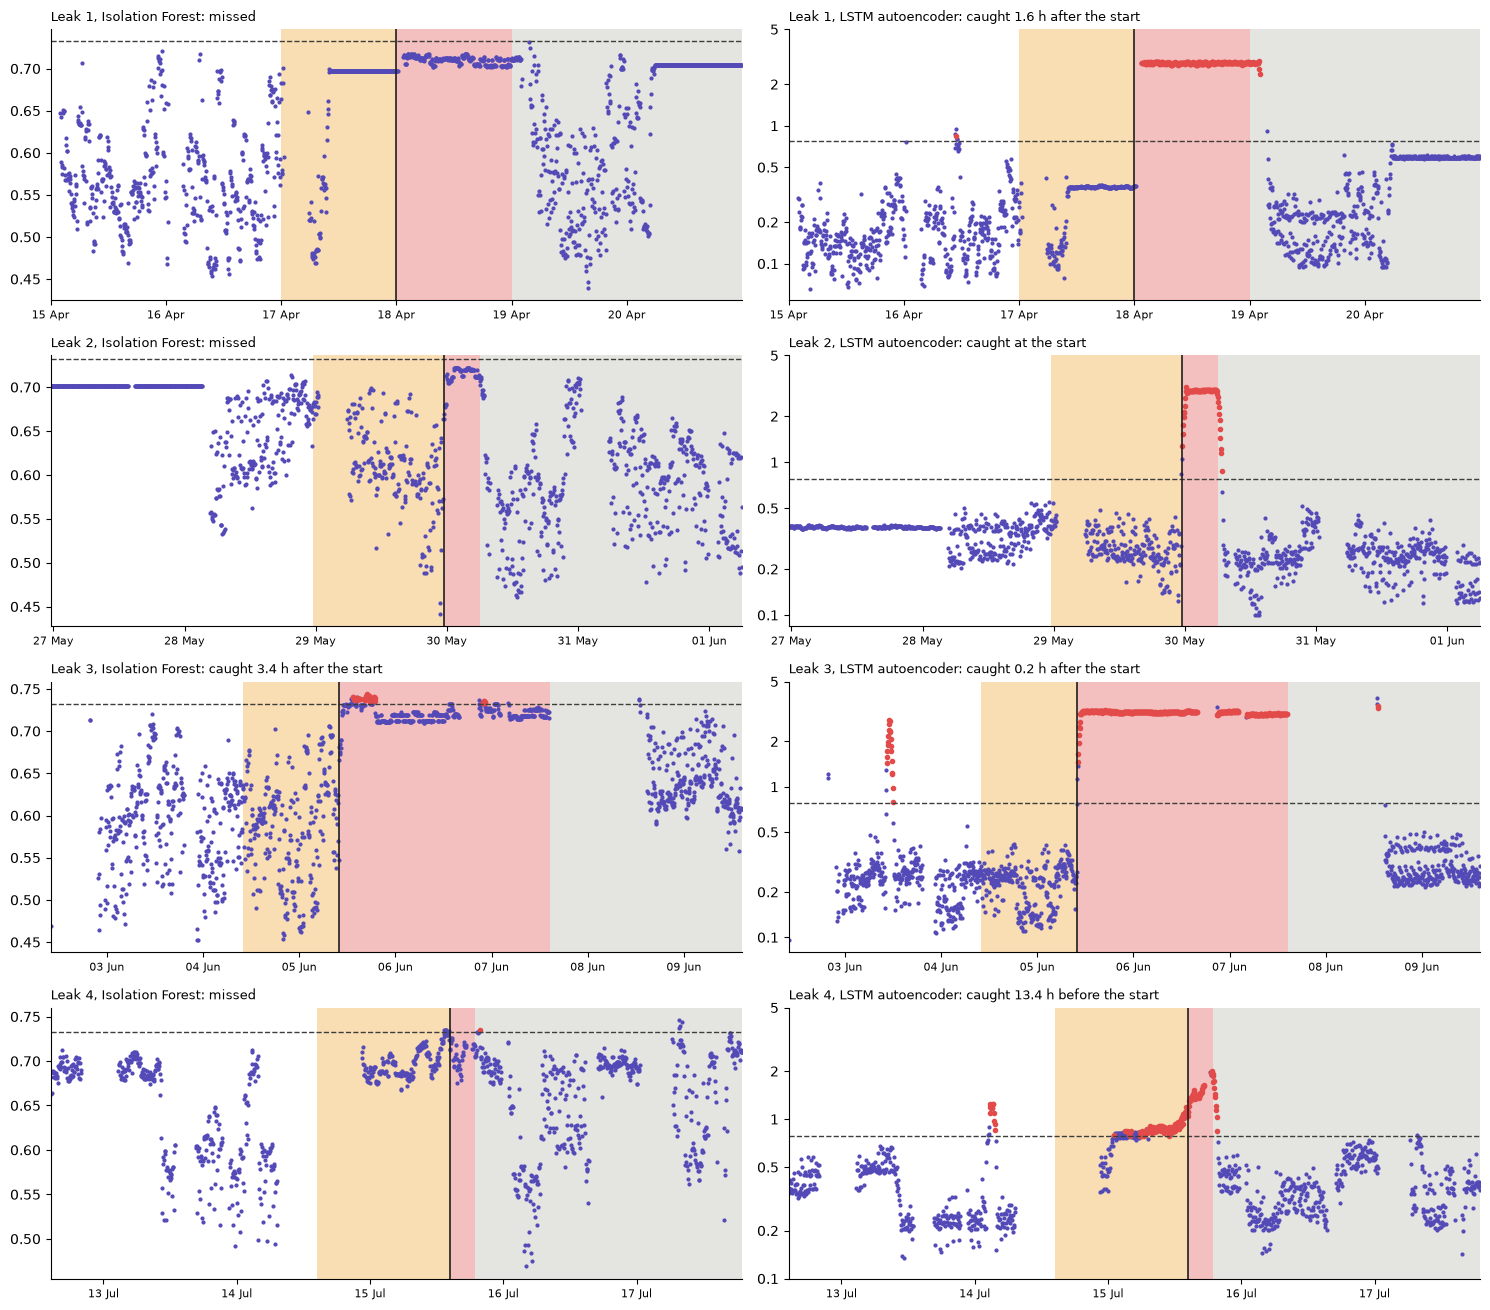

In [25]:
fig, axes = plt.subplots(len(leaks), 2, figsize=(15, 3.3 * len(leaks)))
for i, row in enumerate(leaks.itertuples()):
    in_view = ((df_test["end"] >= row.warning_from - pd.Timedelta(hours=VIEW_BEFORE_HOURS)) & (df_test["end"] <= row.ignored_until)).to_numpy()
    days = pd.date_range((row.warning_from - pd.Timedelta(hours=VIEW_BEFORE_HOURS)).normalize(), row.ignored_until.normalize() + pd.Timedelta(days=1), freq="1D")
    for j, model in enumerate(MODEL_NAMES):
        ax = axes[i, j]
        ax.axvspan(row.warning_from, row.start, color=ZONE_COLORS["warning"], alpha=0.35, linewidth=0)
        ax.axvspan(row.start, row.end, color=ZONE_COLORS["leak"], alpha=0.35, linewidth=0)
        ax.axvspan(row.end, row.ignored_until, color=ZONE_COLORS["ignored"], alpha=0.35, linewidth=0)
        alarm = df_test[f"{model}_alarm"].to_numpy()
        ax.scatter(df_test.loc[in_view & ~alarm, "end"], df_test.loc[in_view & ~alarm, model], s=4, color="#534AB7")
        ax.scatter(df_test.loc[in_view & alarm, "end"], df_test.loc[in_view & alarm, model], s=9, color="#E24B4A")
        ax.axhline(LIMITS[model], color="#3D3D3A", linestyle="--", linewidth=1)
        ax.axvline(row.start, color="#1F1F1E", linewidth=1.2)
        judged = leak_results[(leak_results["model"] == MODEL_NAMES[model]) & (leak_results["leak"] == row.leak)].iloc[0]
        lead = round(judged["lead_time_hours"], 1) if judged["caught"] else None
        verdict = ("missed" if lead is None else f"caught {lead:.1f} h before the start" if lead > 0
                   else f"caught {-lead:.1f} h after the start" if lead < 0 else "caught at the start")
        ax.set_title(f"Leak {row.leak}, {MODEL_NAMES[model]}: {verdict}", fontsize=9.5, loc="left")
        if model == "lstm_autoencoder":
            ax.set_yscale("log")
            ax.set_yticks([0.1, 0.2, 0.5, 1, 2, 5], labels=["0.1", "0.2", "0.5", "1", "2", "5"])
            ax.minorticks_off()
        ax.set_xticks(days, labels=days.strftime("%d %b"), fontsize=8)
        ax.set_xlim(row.warning_from - pd.Timedelta(hours=VIEW_BEFORE_HOURS), row.ignored_until)
        for side in ["top", "right"]:
            ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

### How the Compressor Behaved

> Notebook 3.2 found March hours in which the pump never rested for a whole hour (`drop_bar_per_min` = 0), and notebook 5.1 left them out when it set the limits. How often did that happen in the test months, in each zone? Frozen windows are left out of this table, because their pump never seems to rest only because nothing moves.

In [26]:
real = df_test[~df_test["frozen"]]
never_rested = real.groupby(["leak", "zone"])["drop_bar_per_min"].agg(lambda values: (values == 0).mean()).unstack("zone")
never_rested = never_rested.reindex(columns=["warning", "leak", "ignored"]).drop(index=0).rename(columns={"warning": "warning zone", "leak": "during the leak", "ignored": "ignored zone"})
display(never_rested.map("{:.0%}".format))
print(f"Healthy test windows in which the pump never rested: {(real.loc[real['zone'] == 'healthy', 'drop_bar_per_min'] == 0).mean():.1%}")

zone,warning zone,during the leak,ignored zone
leak,,,
1,0%,100%,7%
2,0%,87%,0%
3,0%,98%,1%
4,0%,67%,0%


Healthy test windows in which the pump never rested: 1.8%


> **What we see:**
>
> - **During the leaks** the pump hardly ever rested (the table above), just like in the March hours that notebook 5.1 left out. The LSTM error jumps far above its limit as soon as that starts. The forest scores these hours at about 0.71, under its limit: its ceiling hides them, as in March. It crosses its limit only during leak 3.
> - **Before the leaks**, in the warning zones, the pump still rested normally. That is why there is no early warning for leaks 1 to 3: the hours before them looked normal to both models (and the warning zone of leak 1 is mostly frozen).
> - **Leak 4 is different:** the LSTM error climbs slowly through the warning zone and crosses the limit many hours before the start, while the pump still rested normally. Something else changed before this leak; notebook 5.3 looks at which signals.
> - There are also LSTM alarms outside the zones, for example about a day before the warning zone of leak 3: these are false alarms.

### False Alarms

> The alarms in healthy time, grouped into events with the 60-minute merge, per week of watched healthy time. The second table shows in which months the false alarm events started.

In [27]:
frozen_alarm_ends = {model: df_test.loc[df_test["frozen"] & df_test[f"{model}_alarm"] & healthy, "end"] for model in MODEL_NAMES}
false_table = pd.DataFrame([{"model": MODEL_NAMES[model], "false alarm events": len(events), "alarm windows in them": int(events["alarms"].sum()),
                             "events with frozen readings": sum(((frozen_alarm_ends[model] >= event.first_alarm) & (frozen_alarm_ends[model] <= event.last_alarm)).any()
                                                                for event in events.itertuples()),
                             "healthy weeks watched": round(healthy_weeks, 1), "per week": round(len(events) / healthy_weeks, 2)}
                            for model, events in false_events.items()]).set_index("model")
display(false_table)
by_month = pd.DataFrame({MODEL_NAMES[model]: pd.to_datetime(events["first_alarm"]).dt.strftime("%m %b").value_counts() for model, events in false_events.items()})
display(by_month.reindex(months.strftime("%m %b")).fillna(0).astype(int).rename(index=lambda label: label[3:]))
print(f"Budget used in March to set the limits: {rules['alarm_rule']['max_false_alarms_per_week']} false alarm event per week")

,false alarm events,alarm windows in them,events with frozen readings,healthy weeks watched,per week
model,,,,,
Isolation Forest,8,174,0,14.8,0.54
LSTM autoencoder,21,1453,1,14.8,1.42


,Isolation Forest,LSTM autoencoder
Apr,1,5
May,6,9
Jun,0,3
Jul,1,4
Aug,0,0
Sep,0,0


Budget used in March to set the limits: 1 false alarm event per week


> **What we see:** the forest stays under the budget of 1 false alarm event per week that set its limit in March; the LSTM goes over it. So the limit of the LSTM, set on March, was a bit too low for the test months, while the limit of the forest was high enough. Both models raise more false alarm events in May than in any other month. One LSTM event holds the frozen readings of June (see "Hours with Frozen Readings").

### Isolation Forest Against the LSTM Autoencoder

> All results of the test months in one table.

In [28]:
rows = []
for model, name in MODEL_NAMES.items():
    own = leak_results[leak_results["model"] == name].set_index("leak")
    rows.append({"model": name, "leaks caught": int(own["caught"].sum()),
                 **{f"lead time leak {leak} (h)": own.loc[leak, "lead_time_hours"] for leak in own.index},
                 "false alarm events": len(false_events[model]), "false alarms per week": len(false_events[model]) / healthy_weeks,
                 "alarms in ignored zones": int(own["alarms_in_ignored_zone"].sum()), "locked limit": LIMITS[model]})
df_results = pd.DataFrame(rows).set_index("model")
formatted = df_results.astype(object)
for column in df_results.columns:
    if column.startswith("lead time"):
        formatted[column] = df_results[column].map(lambda value: "missed" if pd.isna(value) else f"{value:.1f}")
formatted["false alarms per week"] = df_results["false alarms per week"].map("{:.2f}".format)
formatted["locked limit"] = df_results["locked limit"].map("{:.4f}".format)
display(formatted.T)

model,Isolation Forest,LSTM autoencoder
leaks caught,1,4
lead time leak 1 (h),missed,-1.6
lead time leak 2 (h),missed,0.0
lead time leak 3 (h),-3.4,-0.2
lead time leak 4 (h),missed,13.4
false alarm events,8,21
false alarms per week,0.54,1.42
alarms in ignored zones,1,45
locked limit,0.7326,0.7800


> **What we see:** neither model wins on every line.
>
> - **LSTM autoencoder:** catches all 4 leaks, but warns early only for leak 4; the other three it notices at about the start. It raises more false alarms than the budget of March.
> - **Isolation Forest:** raises fewer false alarms, within the budget, but catches only one leak, after its start. During the leaks the pump hardly ever rested, and the ceiling of the forest squeezes exactly such hours under its limit.
>
> In short: the LSTM sees the leaks and the forest mostly does not, but neither sees them coming, except the LSTM before leak 4.

## Save

### What Will Be Written

> - `results/window_scores.parquet`: one row per window of every month: its end, part, zone and leak number, whether its readings were frozen, the score of the forest, the error of the LSTM and its error for every signal, and whether each model raised an alarm. The alarms are computed within each part separately (February, March and the test months), with the locked limits.
> - `results/test_results.csv`: the table above, one row per model.

In [29]:
df_windows["zone"], df_windows["leak"] = zone_of(times=df_windows["end"], leaks=leaks, warning_hours=WARNING_HOURS, ignored_hours=IGNORED_HOURS)
for model in MODEL_NAMES:
    df_windows[f"{model}_alarm"] = False
    for split in SPLIT_NAMES:
        mask = (df_windows["split"] == split).to_numpy()
        df_windows.loc[mask, f"{model}_alarm"] = alarm_windows(scores=df_windows.loc[mask, model].to_numpy(), ends=df_windows.loc[mask, "end"].reset_index(drop=True),
                                                               limit=LIMITS[model], in_a_row=IN_A_ROW, step_minutes=STEP_MINUTES)
signal_error_columns = [f"lstm_error_{signal}" for signal in signals_info["signals"]]
df_scores = pd.concat([df_windows[["end", "split", "zone", "leak", "frozen", "isolation_forest", "lstm_autoencoder", "isolation_forest_alarm", "lstm_autoencoder_alarm"]],
                       pd.DataFrame(signal_errors, columns=signal_error_columns, index=df_windows.index)], axis=1)

print(f"window_scores: {df_scores.shape[0]:,} rows x {df_scores.shape[1]} columns")
display(df_scores.head(3))
check("the test alarms in the file are the alarms counted above", np.array_equal(df_scores.loc[df_scores["split"] == "test", "lstm_autoencoder_alarm"].to_numpy(), df_test["lstm_autoencoder_alarm"].to_numpy())
      and np.array_equal(df_scores.loc[df_scores["split"] == "test", "isolation_forest_alarm"].to_numpy(), df_test["isolation_forest_alarm"].to_numpy()))
for path in [SCORES_FILE, SUMMARY_FILE]:
    print(f"{os.path.relpath(path, ROOT_DIR)}: {'exists, will be replaced' if os.path.exists(path) else 'new file'}")

window_scores: 47,491 rows x 21 columns


,end,split,zone,leak,frozen,isolation_forest,lstm_autoencoder,isolation_forest_alarm,lstm_autoencoder_alarm,lstm_error_TP2,...,lstm_error_H1,lstm_error_DV_pressure,lstm_error_Reservoirs,lstm_error_Oil_temperature,lstm_error_Motor_current,lstm_error_COMP,lstm_error_DV_eletric,lstm_error_Towers,lstm_error_MPG,lstm_error_Pressure_switch
0,2020-02-01 01:00:00,train,healthy,0,False,0.398617,0.049009,False,False,0.062644,...,0.068923,0.048800,0.097409,0.087725,0.056944,0.011624,0.010826,0.029487,0.013791,0.003012
1,2020-02-01 01:05:00,train,healthy,0,False,0.382713,0.040123,False,False,0.042591,...,0.046049,0.044198,0.059368,0.120725,0.049466,0.008453,0.008234,0.029085,0.010136,0.003116
2,2020-02-01 01:10:00,train,healthy,0,False,0.383601,0.034907,False,False,0.030210,...,0.037207,0.043843,0.036396,0.130166,0.048492,0.008169,0.007861,0.028681,0.008372,0.002780


PASS  the test alarms in the file are the alarms counted above
results\window_scores.parquet: new file
results\test_results.csv: new file


### Save the Scores and the Results

In [30]:
os.makedirs(RESULTS_DIR, exist_ok=True)
df_scores.to_parquet(SCORES_FILE, index=False)
df_results.to_csv(SUMMARY_FILE)
for path in [SCORES_FILE, SUMMARY_FILE]:
    print(f"Saved {os.path.relpath(path, ROOT_DIR)} ({os.path.getsize(path) / 1024:,.0f} KB)")

Saved results\window_scores.parquet (4,491 KB)
Saved results\test_results.csv (0 KB)


### Read the Files Back

In [31]:
scores_back = pd.read_parquet(SCORES_FILE)
results_back = pd.read_csv(SUMMARY_FILE, index_col="model")
check("the saved window scores read back the same", scores_back.equals(df_scores.reset_index(drop=True)))
check("the saved results read back the same", np.allclose(results_back.to_numpy(dtype="float64"), df_results.to_numpy(dtype="float64"), equal_nan=True))

PASS  the saved window scores read back the same
PASS  the saved results read back the same


## Result

### Final Result

> If every check passed, the test months were scored with exactly the models and limits of notebook 5.1, and the results are saved. If a check failed, its name is printed.

In [32]:
failed = [name for name, ok in results.items() if not ok]
if results and not failed:
    print(f"ALL CHECKS PASSED ({len(results)} checks)")
else:
    print(f"{len(failed)} of {len(results)} checks FAILED:")
    for name in failed:
        print("  -", name)

ALL CHECKS PASSED (9 checks)


## Summary

> - The test months were scored with exactly the two models and the limits of notebook 5.1: the fingerprints match, and March came out the same as there.
> - **LSTM autoencoder:** caught all 4 leaks. An early warning only for leak 4, many hours before the start; leaks 1 to 3 at about the start. More false alarms per week than the budget of March.
> - **Isolation Forest:** caught only leak 3, a few hours after its start, with fewer false alarms per week than the budget.
> - During the leaks the pump hardly ever rested, like in the March hours left out in notebook 5.1. The LSTM sees such hours clearly; the ceiling of the forest hides them.
> - The test months hold stretches of frozen readings, which February and March never had. Most of the warning zone of leak 1 is frozen, and one long false alarm of the LSTM comes from frozen readings.
> - Notebook 5.3 looks at which signals made the alarms go off. Notebook 5.4 shows what other limits would have given, including the what-if limits of notebook 5.1.
>
> **Next:** `notebooks/5_evaluation/5.3_why_alarms.ipynb`